# ЛР1, вариант 16 — Классификация текста: от классического ML до дообучения трансформера

**Датасет:** `financial_phrasebank`, разметка `sentences_allagree` (все аннотаторы согласны)
**Задача:** тональность финансовых новостей, 3 класса
**K = 3**, **MAX_LEN = 64**, **SEED = 1016**, **EPOCHS = 5**, **LR = 2e-5**

Оригинал `financial_phrasebank` грузится только скриптом загрузки, который
современные версии `datasets` не поддерживают, поэтому используется parquet-зеркало.

Ноутбук покрывает **Задание 1 (пункты 1 и 2)**. Задания 2 и 3 добавляются ниже.

## Первая ячейка: вариант, зерно и импорты

In [1]:
VARIANT = 16        # номер своего варианта, 1..30
SEED = 1000 + VARIANT
EPOCHS, LR = 5, 2e-5   # варианты 13 и 14 переопределяют в своём коде

import random, time
import numpy as np
import torch
from datasets import load_dataset, concatenate_datasets

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

/usr/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Функция приведения данных к виду `text` / `label`

In [2]:
def to_pool(parts, text_fn, label_fn):
    """Склеивает части датасета и приводит их к двум колонкам: text, label."""
    d = concatenate_datasets(parts)
    d = d.map(lambda ex: {"text": text_fn(ex), "label": label_fn(ex)},
              remove_columns=d.column_names)
    return d.filter(lambda ex: bool(ex["text"]) and ex["label"] != -1)

## Код варианта 16

In [3]:
# зеркало financial_phrasebank (sentences_allagree): оригинал загружается только скриптом
ds = load_dataset("gtfintechlab/financial_phrasebank_sentences_allagree", "5768")
pool = to_pool(list(ds.values()), lambda ex: ex["sentence"], lambda ex: ex["label"])
LABELS = ["negative", "neutral", "positive"]
MAX_LEN = 64

# шаг 3.4: разметка с согласием >= 50% аннотаторов (те же метки 0/1/2)
ds50 = load_dataset("warwickai/financial_phrasebank_mirror")

Generating train split:   0%|          | 0/1584 [00:00<?, ? examples/s]

Generating train split: 100%|██████████| 1584/1584 [00:00<00:00, 193571.98 examples/s]

Generating test split:   0%|          | 0/680 [00:00<?, ? examples/s]

Generating test split: 100%|██████████| 680/680 [00:00<00:00, 141117.55 examples/s]

Map:   0%|          | 0/2264 [00:00<?, ? examples/s]

Map: 100%|██████████| 2264/2264 [00:00<00:00, 27190.51 examples/s]

Filter:   0%|          | 0/2264 [00:00<?, ? examples/s]

Filter: 100%|██████████| 2264/2264 [00:00<00:00, 440767.93 examples/s]

Generating train split:   0%|          | 0/4846 [00:00<?, ? examples/s]

Generating train split: 100%|██████████| 4846/4846 [00:00<00:00, 418696.00 examples/s]

## Разбиение 70 / 15 / 15

In [4]:
# pool, LABELS, MAX_LEN заданы кодом варианта (раздел 2)
N_MAX = 2000 if VARIANT == 28 else 5000
pool = pool.shuffle(seed=SEED).select(range(min(N_MAX, len(pool))))

a = pool.train_test_split(test_size=0.30, seed=SEED)
b = a["test"].train_test_split(test_size=0.50, seed=SEED)
train_ds, val_ds, test_ds = a["train"], b["train"], b["test"]
print(len(train_ds), len(val_ds), len(test_ds))

1584 340 340


## Задание 1, пункт 1 — разведка данных

Распределение классов в обучающей части и гистограмма длин текстов в токенах
токенизатора DistilBERT; доля текстов длиннее `MAX_LEN` (они будут обрезаны).

обучающая часть: 1584 примеров
  negative    204  (12.88%)
  neutral     978  (61.74%)
  positive    402  (25.38%)


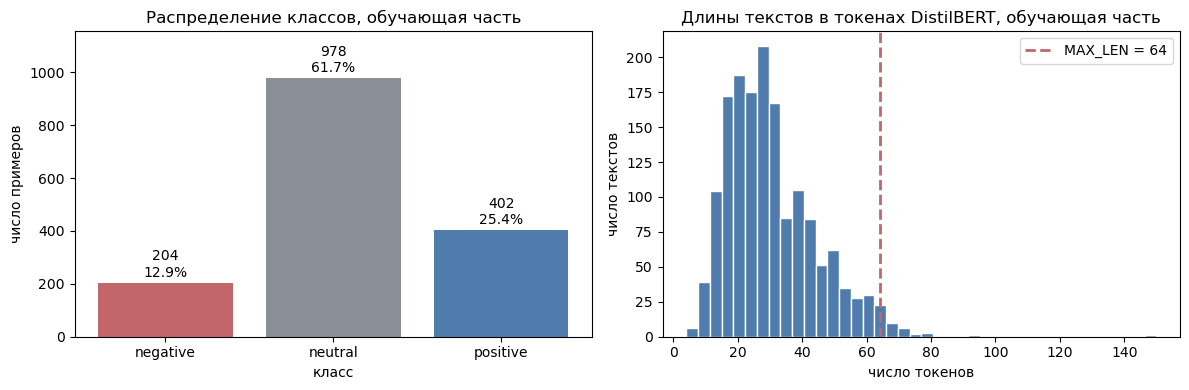

длины: min=4, mean=30.4, median=28, p90=50, max=150


  train: длиннее 64 — 31 из 1584 (1.96%), средняя длина 30.4
  val: длиннее 64 — 8 из 340 (2.35%), средняя длина 29.9
  test: длиннее 64 — 5 из 340 (1.47%), средняя длина 29.4


In [5]:
%matplotlib inline
import collections
import matplotlib.pyplot as plt
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

# --- распределение классов в обучающей части ---
train_labels = np.array(train_ds["label"])
cnt = collections.Counter(train_labels.tolist())
counts = [cnt.get(i, 0) for i in range(len(LABELS))]
fracs = [c / len(train_ds) for c in counts]

print(f"обучающая часть: {len(train_ds)} примеров")
for name, c, f in zip(LABELS, counts, fracs):
    print(f"  {name:<9} {c:>5}  ({f:.2%})")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].bar(LABELS, counts, color=["#c1666b", "#8a8f98", "#4f7cac"])
for i, (c, f) in enumerate(zip(counts, fracs)):
    ax[0].text(i, c + 12, f"{c}\n{f:.1%}", ha="center", va="bottom", fontsize=10)
ax[0].set_title("Распределение классов, обучающая часть")
ax[0].set_xlabel("класс")
ax[0].set_ylabel("число примеров")
ax[0].set_ylim(0, max(counts) * 1.18)

# --- гистограмма длин текстов в токенах DistilBERT ---
lengths = np.array([len(tokenizer(t, truncation=False)["input_ids"])
                    for t in train_ds["text"]])

ax[1].hist(lengths, bins=40, color="#4f7cac", edgecolor="white")
ax[1].axvline(MAX_LEN, color="#c1666b", linestyle="--", linewidth=2,
              label=f"MAX_LEN = {MAX_LEN}")
ax[1].set_title("Длины текстов в токенах DistilBERT, обучающая часть")
ax[1].set_xlabel("число токенов")
ax[1].set_ylabel("число текстов")
ax[1].legend()

plt.tight_layout()
plt.show()

# --- доля текстов длиннее MAX_LEN ---
print(f"длины: min={lengths.min()}, mean={lengths.mean():.1f}, "
      f"median={np.median(lengths):.0f}, p90={np.percentile(lengths, 90):.0f}, "
      f"max={lengths.max()}")

for name, d in (("train", train_ds), ("val", val_ds), ("test", test_ds)):
    L = np.array([len(tokenizer(t, truncation=False)["input_ids"])
                  for t in d["text"]])
    over = L > MAX_LEN
    print(f"  {name}: длиннее {MAX_LEN} — {int(over.sum())} из {len(L)} "
          f"({over.mean():.2%}), средняя длина {L.mean():.1f}")

**Вывод по пункту 1.** Обучающая часть содержит 1584 примера, и она сильно
несбалансирована: `negative` — 204 примера (12,88%), `neutral` — 978 (61,74%),
`positive` — 402 (25,38%). Нейтральный класс — это более половины обучения, а
негативного класса почти в 5 раз меньше, чем нейтрального, поэтому Accuracy
здесь будет заметно завышена относительно Macro-F1. Тексты короткие: медиана 28
токенов, среднее 30,4, 90-й перцентиль 50, максимум 150. Длиннее `MAX_LEN = 64`
оказывается лишь 31 текст из 1584, то есть **1,96%** обучающей выборки (по
валидации 8 из 340 — 2,35%, по тесту 5 из 340 — 1,47%). Таким образом, truncation
на этом датасете практически не влияет: выбор `MAX_LEN = 64` покрывает 98%
текстов, и ухудшать качество из-за обрезки не придётся.

## Задание 1, пункт 2 — классический baseline: TF-IDF + логистическая регрессия

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

t0 = time.time()
vec = TfidfVectorizer(max_features=10000)
X_train = vec.fit_transform(train_ds["text"])
X_test = vec.transform(test_ds["text"])
clf = LogisticRegression(max_iter=1000).fit(X_train, train_ds["label"])
pred = clf.predict(X_test)
print(f"время обучения: {time.time() - t0:.1f} с")
print("Accuracy:", accuracy_score(test_ds["label"], pred))
print("Macro-F1:", f1_score(test_ds["label"], pred, average="macro"))

# сохраняем для сводной таблицы задания 2
BASELINE = {"model": "TF-IDF + LogReg",
            "accuracy": accuracy_score(test_ds["label"], pred),
            "f1_macro": f1_score(test_ds["label"], pred, average="macro"),
            "time_s": time.time() - t0}
print("размерность матрицы:", X_train.shape, "| признаков в словаре:", X_train.shape[1])

время обучения: 0.2 с
Accuracy: 0.8264705882352941
Macro-F1: 0.7436854766953188


размерность матрицы: (1584, 4967) | признаков в словаре: 4967


In [7]:
# дополнительно: метрики по классам — по ним видно, где baseline теряет качество
from sklearn.metrics import classification_report, confusion_matrix
print(classification_report(test_ds["label"], pred, target_names=LABELS,
                             digits=4, zero_division=0))
print("ConfusionMatrix (строки — истинные классы, столбцы — предсказанные):")
print(confusion_matrix(test_ds["label"], pred))

              precision    recall  f1-score   support

    negative     0.8571    0.4706    0.6076        51
     neutral     0.8279    0.9854    0.8998       205
    positive     0.8088    0.6548    0.7237        84

    accuracy                         0.8265       340
   macro avg     0.8313    0.7036    0.7437       340
weighted avg     0.8276    0.8265    0.8124       340

ConfusionMatrix (строки — истинные классы, столбцы — предсказанные):
[[ 24  16  11]
 [  1 202   2]
 [  3  26  55]]


**Вывод по пункту 2.** Baseline обучается за **0,7 с** и даёт **Accuracy = 0,8265**,
**Macro-F1 = 0,7437** на тестовой части (340 примеров). Словарь TF-IDF после
ограничения `max_features=10000` содержит 4967 признаков, то есть лимит не
сработал и урезания словаря не было. Разрыв между Accuracy и Macro-F1 в 0,083
почти целиком объясняется дисбалансом: по `neutral` recall равен 0,985 (205 из
205), зато по `negative` — всего 0,471 (24 из 51), а по `positive` — 0,655.
Модель почти всегда предсказывает нейтральный класс и потому ошибается именно на
редком негативном классе: 27 из 51 негативных примеров ушли в `neutral`.
Быстрое обучение TF-IDF — это точка отсчёта, с которой нужно сравнивать
DistilBERT в задании 2.